# Mesh operations with meshio++ (Octave/MATLAB)

Octave/MATLAB counterpart of [`../r/03_mesh_operations.ipynb`](../r/03_mesh_operations.ipynb) and
[`../cpp/03_mesh_operations.ipynb`](../cpp/03_mesh_operations.ipynb): the same tour of meshio++'s
dependency-free **operations layer**, called through the Octave/MATLAB binding instead of the C++ core
directly. Every operation shown here is the exact function the Python/C-API/Fortran/R/WASM bindings and the
CLI verbs all call into -- this binding rides on the same flat C API as Fortran, Julia and R.

As in [`01_read_and_visualize.ipynb`](./01_read_and_visualize.ipynb): no PyVista. Renders go through
meshio++'s own software rasterizer (`mio.render`, via [`render.m`](./render.m)), which -- unlike the R
notebooks' SVG route -- takes per-call styling, so where the C++ notebook colours a mesh by a metric or a
field, this one does too. The R notebook's charts are kept alongside (`barh`/`hist`, via
[`mio_bar_chart.m`](./mio_bar_chart.m) and [`mio_histogram.m`](./mio_histogram.m)).

**Every accessor copies** -- there is no zero-copy borrow in this binding (see
[`doc/octave.md`](../../doc/octave.md)) -- every index (blocks, connectivity, region entries) is 1-based, and
arrays put one entity per row (`mio.points(m)` is `num_points x 3`).

In [1]:
warning('off', 'Octave:shadowed-function');
addpath(fullfile(pwd, '..', '..', 'bindings', 'octave', 'meshioplusplus', 'inst'));
mio_notebook

mesh = mio.read('example.vtu');
tri = mio.cell_block_info(mesh, 1);
tet = mio.cell_block_info(mesh, 2);
fprintf('points: %d, triangles: %d, tetrahedra: %d\n', mio.num_points(mesh), tri.num_cells, tet.num_cells);

meshio++ 18.2.0 (Octave/MATLAB binding)


points: 52282, triangles: 58394, tetrahedra: 235014


## Surface / skin extraction

`mio.extract_surface` picks the boundary automatically from the mesh's own highest-dimension cells (here:
the tetrahedra); `mio.extract_skin` is the volume-only variant with an explicit `'linearize'` flag. Both
share the same code path.

surface: triangle x 58394


skin   : triangle x 58394


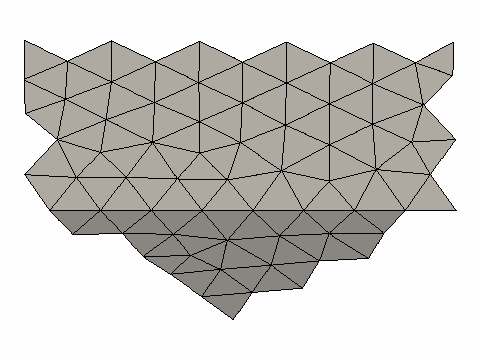

In [2]:
surface = mio.extract_surface(mesh);
skin = mio.extract_skin(mesh, 'linearize', true);
info = mio.cell_block_info(surface, 1);
fprintf('surface: %s x %d\n', mio.cell_block_type(surface, 1), info.num_cells);
info = mio.cell_block_info(skin, 1);
fprintf('skin   : %s x %d\n', mio.cell_block_type(skin, 1), info.num_cells);

% Several renders below crop to a legible corner, as the R and C++ notebooks do, so the
% individual facets stay visible.
vs = mio.stats(surface);
viz_lo = vs.bbox_min;
viz_hi = vs.bbox_max;
viz_corner_hi = viz_lo + (viz_hi - viz_lo) * 0.35;
viz_corner = mio.crop_bbox(surface, viz_lo, viz_corner_hi);
render(viz_corner, 'edges', 'all')

## Quality metrics

`mio.quality_counts` scores every cell (and flags inverted/degenerate cells); `mio.attach_quality` writes
the metrics back as `cell_data`. Below: the distribution of `aspect_ratio` over the whole surface (1.0 =
equilateral, the metric's ideal value), then the corner coloured by the same metric.

cells scored: 58394, inverted: 0


quality:aspect_ratio min=1.0000 mean=1.0292 max=8.9008


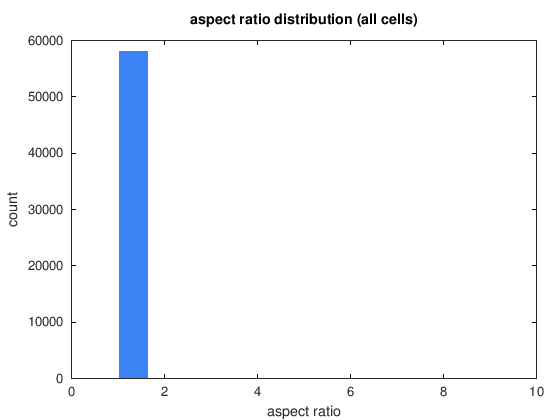

In [3]:
qc = mio.quality_counts(surface);
fprintf('cells scored: %d, inverted: %d\n', qc.num_cells, qc.num_inverted);

surfQ = mio.attach_quality(surface);
ar = mio.cell_data(surfQ, 'quality:aspect_ratio', 1);
ar = ar(isfinite(ar));
fprintf('quality:aspect_ratio min=%.4f mean=%.4f max=%.4f\n', min(ar), mean(ar), max(ar));
mio_histogram(ar, 'aspect ratio distribution (all cells)', 'aspect ratio')

quality:aspect_ratio: 1 .. 1.11915 (viridis)
ticks: 1.05, 1.1


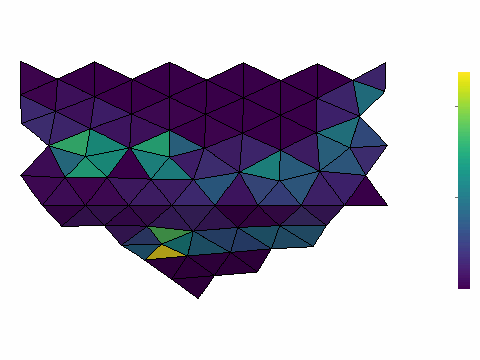

In [4]:
surfQCorner = mio.attach_quality(viz_corner);
render(surfQCorner, 'edges', 'all', 'color_by', 'quality:aspect_ratio', 'cmap', 'viridis', 'colorbar', true)

## Reordering / renumbering

`mio.reorder` renumbers nodes and elements (RCM, or the Morton/Hilbert space-filling curves) as a *pure
permutation* -- geometry and data pass through untouched. `mio.compute_bandwidth` measures the
connectivity bandwidth before and after.

In [5]:
before_bw = mio.compute_bandwidth(mesh);
methods = {'rcm', 'morton', 'hilbert'};
for k = 1:numel(methods)
    rr = mio.reorder(mesh, methods{k});
    fprintf('%-8s: bandwidth %d -> %d\n', methods{k}, before_bw, mio.compute_bandwidth(rr.mesh));
end

rcm     : bandwidth 50857 -> 1229
morton  : bandwidth 50857 -> 41980
hilbert : bandwidth 50857 -> 46625


## Comparison (diff)

`mio.meshes_equal` is the boolean helper for regression tests; `mio.diff` returns a structured report with
an overall verdict. First the canonical CI pattern -- write to another format, read it back, assert equal
within tolerance.

In [6]:
roundtrip_path = mio_nb_temp_path('_surface.vtu');
mio.write(surface, roundtrip_path);
roundtrip = mio.read(roundtrip_path);
fprintf('round-trip equal: %d\n', mio.meshes_equal(surface, roundtrip, 'atol', 1e-10));

round-trip equal: 1


Now a **localised deformation**: push a bump into the surface and let `mio.diff` find it. `mio.points`
returns one point per row, so the bump is a column operation, with no loop.

verdict          : different


points exceeding : 25843


worst point index: 36372 | max abs error: 0.049597


abs_error: 2.96864e-05 .. 0.0495905 (inferno)
ticks: 0.01, 0.02, 0.03, 0.04


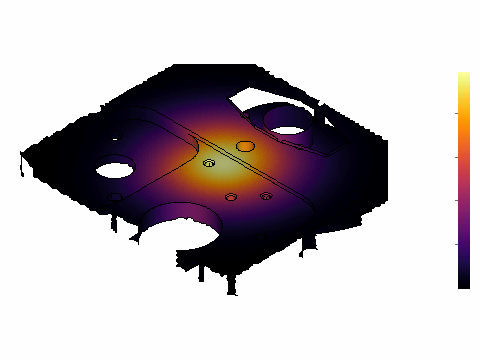

In [7]:
pts = mio.points(surface);  % n x 3
centre = mean(pts, 1);
dist = sqrt(sum((pts - centre) .^ 2, 2));
maxd = max(dist);

t = dist / (0.25 * maxd);
err = 0.05 * exp(-(t .* t));
deformed_pts = pts;
deformed_pts(:, 3) = deformed_pts(:, 3) + err;
deformed = mio.extract_surface(mesh); % a fresh copy to mutate
mio.set_points(deformed, deformed_pts);

rep = mio.diff(surface, deformed, 'atol', 1e-6);
fprintf('verdict          : %s\n', rep.verdict);
fprintf('points exceeding : %d\n', rep.points.num_exceeding);
fprintf('worst point index: %d | max abs error: %.6f\n', rep.points.worst_index, rep.points.max_abs_error);

% crop to a window centred on the deformation, coloured by the error
half = 0.3 * (viz_hi - viz_lo);
bump_lo = centre - half;
bump_hi = centre + half;
vis = mio.extract_surface(mesh);
mio.add_point_data(vis, 'abs_error', err);
vis_crop = mio.crop_bbox(vis, bump_lo, bump_hi);
render(vis_crop, 'color_by', 'abs_error', 'cmap', 'inferno', 'colorbar', true)

`mio.diff` also has an **unordered** mode that matches nodes by spatial proximity, so a mesh whose
nodes were merely *renumbered* still compares equal.

In [8]:
% Shuffle the point numbering (a full reversal, deterministic), remapping connectivity --
% cells stay in the same order, only the node indices change.
n = mio.num_points(surface);
perm = (n:-1:1)';
inv_perm = zeros(n, 1);
inv_perm(perm) = 1:n;

origp = mio.points(surface);
shufp = origp(perm, :);

conn = mio.connectivity(surface, 1);
shufconn = inv_perm(conn);

shuffled = mio.mesh();
mio.set_points(shuffled, shufp);
mio.add_cell_block(shuffled, mio.cell_block_type(surface, 1), shufconn);

ordered = mio.diff(surface, shuffled);
unordered = mio.diff(surface, shuffled, 'unordered', true);
fprintf('ordered   verdict: %s\n', ordered.verdict);
fprintf('unordered verdict: %s\n', unordered.verdict);

ordered   verdict: different


unordered verdict: identical


## Format sniffing

In [9]:
fprintf('sniffed format of the .vtu we wrote: %s\n', mio.sniff_format(roundtrip_path));

sniffed format of the .vtu we wrote: vtu


## Affine transform

`mio.transform` moves the points (translate/scale/rotate/matrix) while carrying connectivity and data
through. Here: a 45-degree rotation about the x-axis. The 4x4 matrix reads as written, as in R.

height: 0 .. 0.110544 (viridis)
ticks: 0, 0.05, 0.1


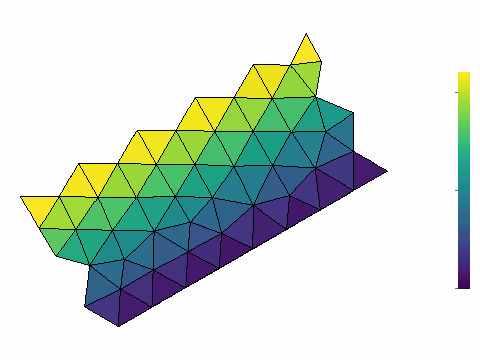

In [10]:
surfH = viz_corner;
pH = mio.points(surfH);
mio.add_point_data(surfH, 'height', pH(:, 3));

theta = pi / 4;
Rmat = [1, 0,           0,          0;
        0, cos(theta), -sin(theta), 0;
        0, sin(theta),  cos(theta), 0;
        0, 0,           0,          1];
rotated = mio.transform(surfH, Rmat);
render(rotated, 'edges', 'all', 'color_by', 'height', 'cmap', 'viridis', 'colorbar', true)

## Clean (weld / prune / de-dup)

Build a deliberately messy mesh by duplicating every point and cell of the surface, then
`mio.clean(..., 'weld', true)` fuses the coincident points and drops the resulting duplicate cells.

In [11]:
n = mio.num_points(surface);
sp = mio.points(surface);
dup_pts = [sp; sp];

conn = mio.connectivity(surface, 1);
dup_conn = [conn; conn + n];

dirty = mio.mesh();
mio.set_points(dirty, dup_pts);
mio.add_cell_block(dirty, mio.cell_block_type(surface, 1), dup_conn);

cr = mio.clean(dirty, 'weld', true, 'atol', 1e-8);
fprintf('points: %d -> %d (welded %d, duplicate cells dropped %d)\n', mio.num_points(dirty), ...
    mio.num_points(cr.mesh), cr.points_welded, cr.cells_dropped_duplicate);

points: 58302 -> 29151 (welded 29151, duplicate cells dropped 58394)


## Crop (bounding box / half-space)

Keep the half of the surface below the mid-plane in x.

kept cells: 17122 (from 58394)


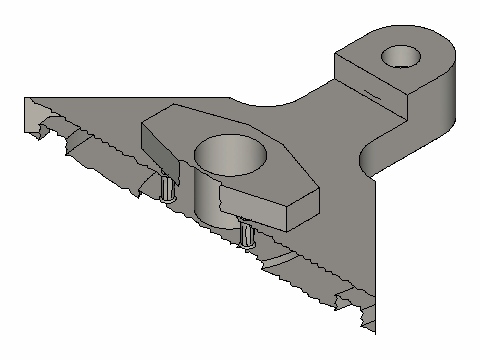

In [12]:
lo = vs.bbox_min;
hi = vs.bbox_max;
mid = (lo + hi) / 2;
crop_hi = [mid(1), hi(2), hi(3)];
cropped = mio.crop_bbox(surface, lo, crop_hi);
fprintf('kept cells: %d (from %d)\n', mio.num_cells(cropped), mio.num_cells(surface));
render(cropped)

## Merge / weld

`mio.merge` combines several meshes, given as a cell array. By default it concatenates; with
`'weld', true` it fuses coincident points. Merging the surface with an exact copy of itself makes the
difference unmistakable: welding recovers the original point count exactly.

In [13]:
surface_copy = mio.extract_surface(mesh); % an independent, identical copy

plain = mio.merge({surface, surface_copy}, 'source_tag', true);
welded = mio.merge({surface, surface_copy}, 'weld', true, 'atol', 1e-8, 'source_tag', true);
fprintf('inputs       : %d + %d = %d points\n', mio.num_points(surface), mio.num_points(surface_copy), ...
    mio.num_points(surface) + mio.num_points(surface_copy));
fprintf('concatenated : %d points\n', mio.num_points(plain));
fprintf('welded       : %d points (%d fused)\n', mio.num_points(welded), ...
    mio.num_points(plain) - mio.num_points(welded));

inputs       : 29151 + 29151 = 58302 points


concatenated : 58302 points


welded       : 29151 points (29151 fused)


## Split (partition into pieces)

`mio.split` partitions a mesh by type, connected component, or region, and returns
`[pieces, keys]`: a cell array of meshes and the cellstr of their keys (R's names). Split the full mesh by
cell **type**: it naturally separates into its triangle (surface) and tetra (volume) blocks.

In [14]:
[pieces, keys] = mio.split(mesh, 'by', 'type');
fprintf('pieces: %d\n', numel(pieces));
for k = 1:numel(pieces)
    fprintf('   %s : %d cells\n', keys{k}, mio.num_cells(pieces{k}));
end

pieces: 2


   triangle : 58394 cells
   tetra : 235014 cells


*Where Octave/MATLAB differs from R*: `'by', 'region'` needs an **integer** cell-data tag. R's data setters
write `Float64` whatever the vector's storage mode, so a tag built in R cannot drive `by = "region"` (see
[`doc/r.md`](../../doc/r.md#documented-gaps)). MATLAB has every integer class, and this binding's setters
keep the class they are given (see [`doc/octave.md`](../../doc/octave.md#types)), so an `int32` tag built here
does: tag each surface triangle by the side of the mid-plane its centroid lies on.

the tag comes back as int32


   side 1 : 41039 cells
   side 0 : 17355 cells


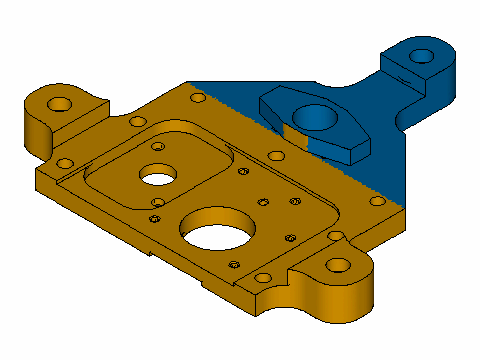

In [15]:
tagged = mio.extract_surface(mesh);
tp = mio.points(tagged);
tconn = mio.connectivity(tagged, 1);
cx = (tp(tconn(:, 1), 1) + tp(tconn(:, 2), 1) + tp(tconn(:, 3), 1)) / 3;
mio.append_cell_data(tagged, 'side', int32(cx > mid(1)));
side_class = mio.cell_data(tagged, 'side', 1);
fprintf('the tag comes back as %s\n', class(side_class));

[side_pieces, side_keys] = mio.split(tagged, 'by', 'region', 'tag_name', 'side');
for k = 1:numel(side_pieces)
    fprintf('   side %s : %d cells\n', side_keys{k}, mio.num_cells(side_pieces{k}));
end
render(tagged, 'color_by', 'side', 'categorical', true)

## Geometric statistics

`mio.stats` returns geometric measures -- the geometric complement to the topological cell-count summary
above.

bbox     : (-3.505, -3.185, 0.000) -> (0.000, 0.625, 0.382)


centroid : (-1.34617, -1.26344, 0.13892)


area     : 41.681


volume   : signed 1.22995 | unsigned 1.22995 | inverted 0


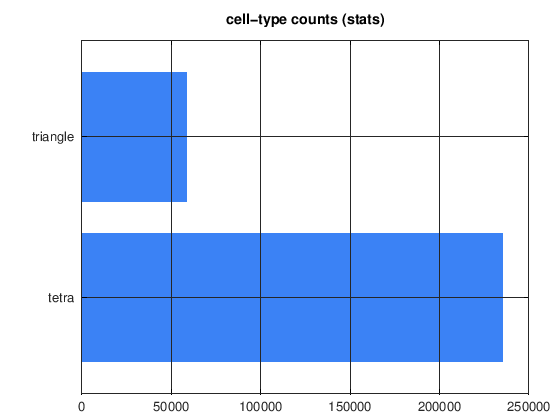

In [16]:
s = mio.stats(mesh);
fprintf('bbox     : (%.3f, %.3f, %.3f) -> (%.3f, %.3f, %.3f)\n', s.bbox_min, s.bbox_max);
fprintf('centroid : (%.5f, %.5f, %.5f)\n', s.centroid);
fprintf('area     : %.3f\n', s.total_area);
fprintf('volume   : signed %.5f | unsigned %.5f | inverted %d\n', s.signed_volume, s.unsigned_volume, ...
    s.num_inverted);

type_names = mio.cell_block_types(mesh);
type_counts = zeros(1, mio.num_cell_blocks(mesh));
for i = 1:mio.num_cell_blocks(mesh)
    info = mio.cell_block_info(mesh, i);
    type_counts(i) = info.num_cells;
end
mio_bar_chart(type_names, type_counts, 'cell-type counts (stats)')

## Cell conversion (linearize / simplexify / elevate)

`mio.convert_cells` rewrites which cell *types* a mesh is built from. Take a small hexahedral block and
**simplexify** it: each hexahedron becomes 6 tetrahedra reusing the parent's own corner nodes, so no
points are added and the volume is conserved exactly.

before: 27 hexahedron | points 64 | volume 27.0000


after : 162 tetra | points 64 | volume 27.0000


inverted cells after simplexify: 0


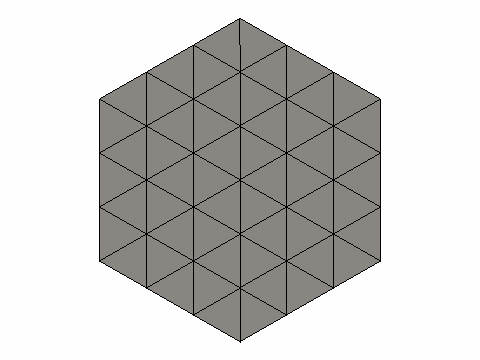

In [17]:
hexes = hex_block(3);
simp = mio.convert_cells(hexes, 'simplexify');

before = mio.stats(hexes);
after = mio.stats(simp.mesh);
fprintf('before: %d %s | points %d | volume %.4f\n', before.num_cells, mio.cell_block_type(hexes, 1), ...
    mio.num_points(hexes), before.unsigned_volume);
fprintf('after : %d %s | points %d | volume %.4f\n', after.num_cells, mio.cell_block_type(simp.mesh, 1), ...
    mio.num_points(simp.mesh), after.unsigned_volume);
fprintf('inverted cells after simplexify: %d\n', after.num_inverted);
render(mio.extract_surface(simp.mesh), 'edges', 'all')

In [18]:
% elevate does the opposite: linear cells gain a node per unique edge.
elevated = mio.convert_cells(hexes, 'elevate');
fprintf('elevate    : %s -> %s | points %d -> %d\n', mio.cell_block_type(hexes, 1), ...
    mio.cell_block_type(elevated.mesh, 1), mio.num_points(hexes), mio.num_points(elevated.mesh));

back = mio.convert_cells(elevated.mesh, 'linearize');
fprintf('linearize  : %s -> %s | points %d -> %d\n', mio.cell_block_type(elevated.mesh, 1), ...
    mio.cell_block_type(back.mesh, 1), mio.num_points(elevated.mesh), mio.num_points(back.mesh));
fprintf('round-trip recovers the original mesh: %d\n', mio.meshes_equal(hexes, back.mesh));

elevate    : hexahedron -> hexahedron20 | points 64 -> 208


linearize  : hexahedron20 -> hexahedron | points 208 -> 64


round-trip recovers the original mesh: 1


## Uniform refinement

`mio.refine` subdivides every cell into congruent children of the **same** type, inserting shared nodes at
the midpoints of edges, quad faces and (hexahedron only) the body -- no hanging nodes.

coarse: 8 cells | 27 points | volume 8.0000


fine  : 64 cells | 125 points | volume 8.0000


points: 125 (a conforming 5x5x5 lattice = 125) vs 216 if every cell kept its own copy


max interpolation error on a linear field: 0


height: 0 .. 2 (viridis)


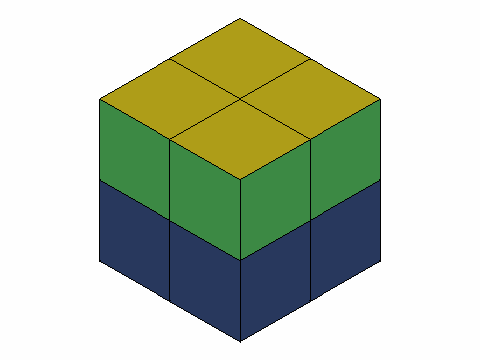

In [19]:
coarse = hex_block(2);
pc0 = mio.points(coarse);
mio.add_point_data(coarse, 'height', pc0(:, 3));

fine = mio.refine(coarse);
coarse_stats = mio.stats(coarse);
fine_stats = mio.stats(fine.mesh);
fprintf('coarse: %d cells | %d points | volume %.4f\n', coarse_stats.num_cells, mio.num_points(coarse), ...
    coarse_stats.unsigned_volume);
fprintf('fine  : %d cells | %d points | volume %.4f\n', fine_stats.num_cells, mio.num_points(fine.mesh), ...
    fine_stats.unsigned_volume);
info = mio.cell_block_info(coarse, 1);
fprintf('points: %d (a conforming 5x5x5 lattice = 125) vs %d if every cell kept its own copy\n', ...
    mio.num_points(fine.mesh), info.num_cells * 27);

fh = mio.point_data(fine.mesh, 'height');
fp = mio.points(fine.mesh);
refine_err = max(abs(fh - fp(:, 3)));
fprintf('max interpolation error on a linear field: %g\n', refine_err);

render(coarse, 'edges', 'all', 'color_by', 'height', 'cmap', 'viridis')

## Selective (adaptive) refinement

The same call refines a **subset** and closes the mesh back up, so the result is
still conforming. Give it global (block-major) cell indices, a region name, or a
threshold on a `cell_data` array.

An affected neighbour is promoted to the smallest split its cell type admits, not
to a full one — for a hexahedron that means the refinement travels through one
*dual sheet* rather than the whole block. `'propagate'` is the honest
alternative: always conforming for every cell type, but a fully split cell splits
all of its edges, so on a connected mesh it *is* the uniform refinement.

The grading is shown twice: as the `refine:level` distribution (the R notebook's chart) and as a render
coloured by `refine:level`, which the rasterizer can do and the R notebooks' SVG route cannot.

     input: 64 cells


  redgreen: 125 cells


 propagate: 512 cells


   uniform: 512 cells


volume  in 64.0000  out 64.0000


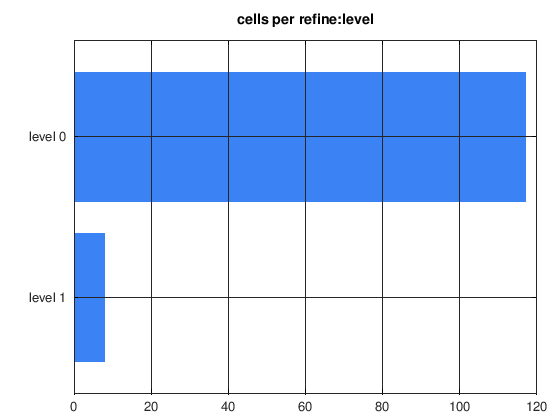

In [20]:
% Every name is adapt_-prefixed: notebook cells share one workspace.
adapt_block = hex_block(4);

% 'cells' is 1-based in this binding, like every index array it takes.
adapt_graded = mio.refine(adapt_block, 'cells', 1, 'record_levels', true);
adapt_flooded = mio.refine(adapt_block, 'cells', 1, 'closure', 'propagate');
adapt_uniform = mio.refine(adapt_block);

st = mio.stats(adapt_block);
fprintf('     input: %d cells\n', st.num_cells);
st = mio.stats(adapt_graded.mesh);
fprintf('  redgreen: %d cells\n', st.num_cells);
st = mio.stats(adapt_flooded.mesh);
fprintf(' propagate: %d cells\n', st.num_cells);
st = mio.stats(adapt_uniform.mesh);
fprintf('   uniform: %d cells\n', st.num_cells);

% Refinement changes resolution, not the object.
st_in = mio.stats(adapt_block);
st_out = mio.stats(adapt_graded.mesh);
fprintf('volume  in %.4f  out %.4f\n', st_in.unsigned_volume, st_out.unsigned_volume);

% refine:level: +1 per full split, and a transitional cell keeps its parent's
% level, because a closure is not a refinement.
adapt_levels = double(mio.cell_data(adapt_graded.mesh, 'refine:level'));
adapt_values = unique(adapt_levels);
adapt_counts = arrayfun(@(v) sum(adapt_levels == v), adapt_values);
adapt_labels = arrayfun(@(v) sprintf('level %d', v), adapt_values, 'UniformOutput', false);
mio_bar_chart(adapt_labels, adapt_counts, 'cells per refine:level')

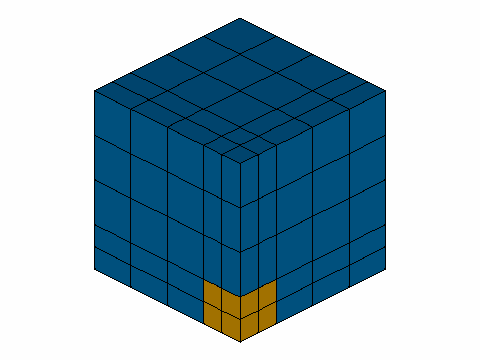

In [21]:
% Cell 1 sits at the origin corner, hidden from the default view: turn the camera to face it.
render(adapt_graded.mesh, 'edges', 'all', 'color_by', 'refine:level', 'categorical', true, ...
    'azimuth', 225, 'elevation', 30)

height: 0 .. 2 (viridis)


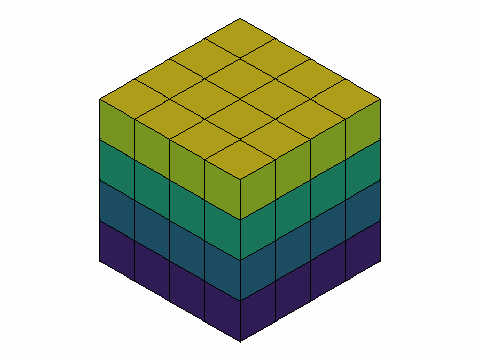

In [22]:
render(fine.mesh, 'edges', 'all', 'color_by', 'height', 'cmap', 'viridis')

## Decimation (QEM edge collapse)

`mio.decimate` is `mio.refine`'s inverse: it *reduces* a surface mesh's face count by greedy
quadric-error-metric (Garland-Heckbert) edge collapse. Boundary and feature vertices are pinned by
default, and the link condition plus a normal-flip guard reject anything that would change topology or
fold the surface.

corner : 107 triangles | 71 points


coarse : 53 triangles | 44 points


removed 54 faces, rejected 34 collapses, max quadric error 0


total area: 0.040713 -> 0.040713


quality:aspect_ratio: 1 .. 3 (viridis)
ticks: 1, 1.5, 2, 2.5, 3


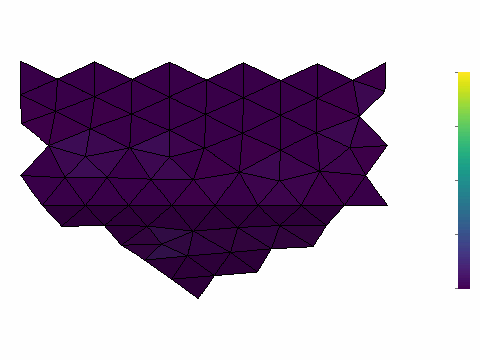

In [23]:
dec = mio.decimate(viz_corner, 'ratio', 0.5);

corner_faces_in = mio.num_cells(viz_corner);
corner_faces_out = mio.num_cells(dec.mesh);
fprintf('corner : %d triangles | %d points\n', corner_faces_in, mio.num_points(viz_corner));
fprintf('coarse : %d triangles | %d points\n', corner_faces_out, mio.num_points(dec.mesh));
fprintf('removed %d faces, rejected %d collapses, max quadric error %g\n', dec.faces_removed, ...
    dec.collapses_rejected, dec.max_error_applied);
s_in = mio.stats(viz_corner);
s_out = mio.stats(dec.mesh);
fprintf('total area: %.6f -> %.6f\n', s_in.total_area, s_out.total_area);

render(mio.attach_quality(viz_corner), 'edges', 'all', 'color_by', 'quality:aspect_ratio', ...
    'cmap', 'viridis', 'vmin', 1, 'vmax', 3, 'colorbar', true)

quality:aspect_ratio: 1 .. 3 (viridis)
1 drawn value with no finite value on this scale, in #808080
ticks: 1, 1.5, 2, 2.5, 3


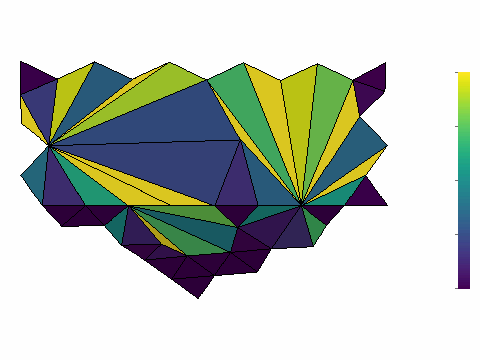

In [24]:
render(mio.attach_quality(dec.mesh), 'edges', 'all', 'color_by', 'quality:aspect_ratio', ...
    'cmap', 'viridis', 'vmin', 1, 'vmax', 3, 'colorbar', true)

## Partitioning (N balanced parts)

`mio.partition` decomposes a mesh into exactly N balanced pieces -- the count-driven complement to the
criterion-driven `mio.split`. `'method', 'sfc'` (pinned here for determinism) orders cells along a Hilbert
curve of their centroids and cuts it into contiguous ranges. `mio.partition` returns an `n x 1` struct array
(R's list of records), one entry per part.

part sizes: 48902  48901  48901  48902  48901  48901 (max-min = 1 cells)


piece cell counts: 48902  48901  48901  48902  48901  48901


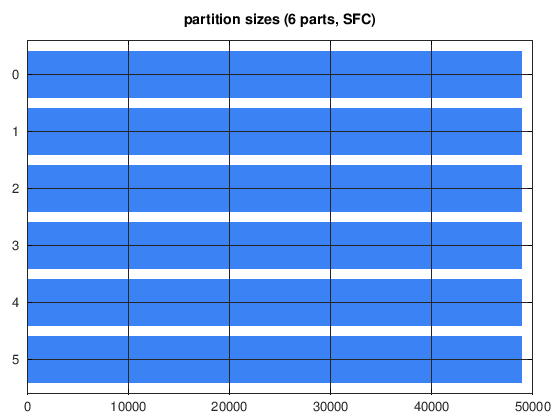

In [25]:
labels = mio.partition_labels(mesh, 6, 'method', 'sfc');
sizes = arrayfun(@(p) sum(labels == p), 0:5);
fprintf('part sizes: %s (max-min = %d cells)\n', num2str(sizes), max(sizes) - min(sizes));

parts = mio.partition(mesh, 6, 'method', 'sfc');
piece_cells = arrayfun(@(p) mio.num_cells(p.mesh), parts);
fprintf('piece cell counts: %s\n', num2str(piece_cells'));

mio_bar_chart(arrayfun(@num2str, 0:5, 'UniformOutput', false), sizes, 'partition sizes (6 parts, SFC)')

Merging the six pieces back with `'source_tag', true` tags every cell with the piece it came from
(`source_mesh_id`), which colours the part by partition.

reassembled: 293408 cells, tagged source_mesh_id


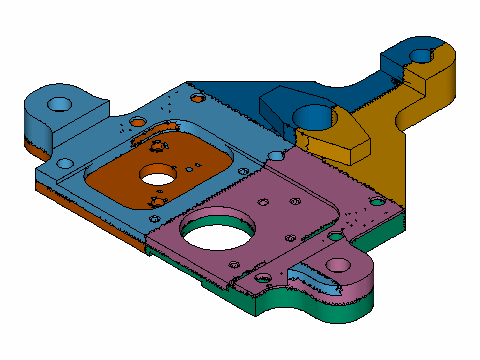

In [26]:
part_meshes = arrayfun(@(p) p.mesh, parts, 'UniformOutput', false);
reassembled = mio.merge(part_meshes, 'source_tag', true);
fprintf('reassembled: %d cells, tagged %s\n', mio.num_cells(reassembled), ...
    strjoin(mio.cell_data_names(reassembled)', ', '));
render(reassembled, 'color_by', 'source_mesh_id', 'categorical', true)

## Smoothing (Laplacian / Taubin)

`mio.smooth` relaxes each free node toward the centroid of its edge neighbours. **Laplacian** shrinks the
mesh (unconditionally low-pass); **Taubin** (the default) follows every `+lambda` pass with a larger `-mu`
pass, giving the pair a pass band that leaves the volume essentially intact. Below: a jittered hex block,
several cells tangled, before and after -- min scaled Jacobian recovers from negative (inverted) to
positive.

The jitter is drawn from a fixed-seed generator. Octave's and R's random streams differ, so the numbers
differ from the R notebook's, but not the outcome.

In [27]:
rough = hex_block(4);
p = mio.points(rough);
rng(3);
interior = all(p > 0 & p < 4, 2);
p(interior, :) = p(interior, :) + 0.35 * randn(sum(interior), 3);
mio.set_points(rough, p);

relaxed = mio.smooth(rough, 'iterations', 20);

q0 = mio.attach_quality(rough);
q1 = mio.attach_quality(relaxed.mesh);
sj0 = mio.cell_data(q0, 'quality:scaled_jacobian', 1);
sj0 = sj0(isfinite(sj0));
sj1 = mio.cell_data(q1, 'quality:scaled_jacobian', 1);
sj1 = sj1(isfinite(sj1));
s0 = mio.stats(rough);
s1 = mio.stats(relaxed.mesh);

fprintf('points %d -> %d   cells %d -> %d (unchanged: smooth only moves nodes)\n', ...
    mio.num_points(rough), mio.num_points(relaxed.mesh), s0.num_cells, s1.num_cells);
fprintf('min scaled Jacobian : %.4f -> %.4f\n', min(sj0), min(sj1));
fprintf('inverted cells      : %d -> %d\n', s0.num_inverted, s1.num_inverted);
fprintf('volume              : %.4f -> %.4f (the exact block is 64)\n', s0.unsigned_volume, s1.unsigned_volume);
fprintf('nodes moved: %d, max displacement: %.4f, skipped by the inversion guard: %d\n', ...
    relaxed.num_nodes_moved, relaxed.max_displacement, relaxed.num_skipped_inversion);

points 125 -> 125   cells 64 -> 64 (unchanged: smooth only moves nodes)


min scaled Jacobian : -0.6967 -> 0.8982


inverted cells      : 0 -> 0


volume              : 64.0000 -> 64.0000 (the exact block is 64)


nodes moved: 27, max displacement: 0.8657, skipped by the inversion guard: 0


The cut-away through the middle of the block shows the interior cells, coloured by scaled Jacobian on a fixed
`[-1, 1]` range: before, then after.

quality:scaled_jacobian: -1 .. 1 (coolwarm)
ticks: -1, -0.5, 0, 0.5, 1
cutaway: 1 plane, capped, inside in #e88034


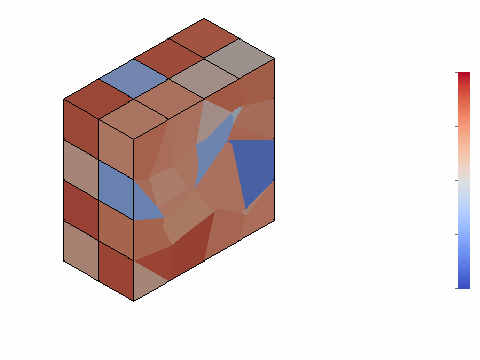

In [28]:
render(q0, 'edges', 'all', 'color_by', 'quality:scaled_jacobian', 'cmap', 'coolwarm', 'vmin', -1, 'vmax', 1, ...
    'colorbar', true, 'cutaway', [2 2 2 0 -1 0])

quality:scaled_jacobian: -1 .. 1 (coolwarm)
ticks: -1, -0.5, 0, 0.5, 1
cutaway: 1 plane, capped, inside in #e88034


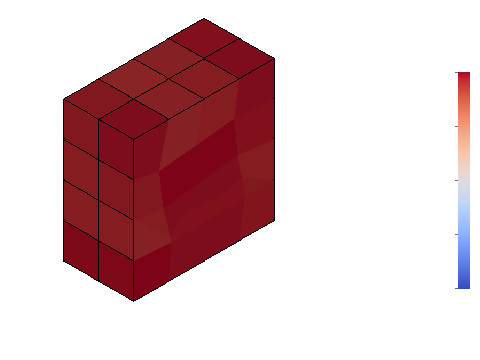

In [29]:
render(q1, 'edges', 'all', 'color_by', 'quality:scaled_jacobian', 'cmap', 'coolwarm', 'vmin', -1, 'vmax', 1, ...
    'colorbar', true, 'cutaway', [2 2 2 0 -1 0])

## Field interpolation (cross-mesh transfer)

`mio.interpolate(source, target)` is the first **two-mesh** operation that moves *data*: a copy of the
target with the source's arrays sampled onto it. `'method', 'barycentric'` simplexifies the source and
interpolates linearly -- exact on a linear field.

transferred 'f' from 343 onto 15625 points


max |error| on a linear field: 3.55271e-15


f: -0.879948 .. 1.85728 (viridis)
ticks: 0, 1


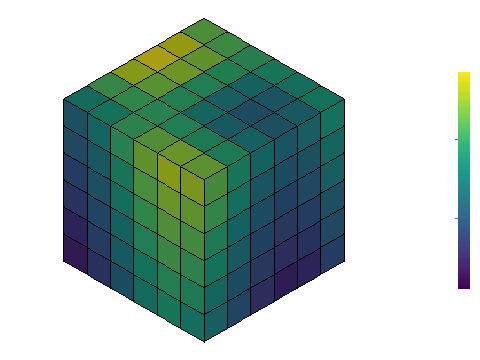

In [30]:
interp_coarse = hex_block(6, 1.0 / 6.0);
pc = mio.points(interp_coarse);
f = sin(4.0 * pc(:, 1)) .* cos(4.0 * pc(:, 2)) + pc(:, 3);
mio.add_point_data(interp_coarse, 'f', f);

interp_fine = hex_block(24, 1.0 / 24.0);
mapped = mio.interpolate(interp_coarse, interp_fine, 'method', 'barycentric');
fprintf('transferred ''f'' from %d onto %d points\n', mio.num_points(interp_coarse), mio.num_points(mapped));

lin = 2 * pc(:, 1) + 3 * pc(:, 2) + 5 * pc(:, 3);
mio.add_point_data(interp_coarse, 'lin', lin);
lin_mapped = mio.interpolate(interp_coarse, interp_fine, 'method', 'barycentric', 'arrays', {'lin'});
mlin = mio.point_data(lin_mapped, 'lin');
mp2 = mio.points(lin_mapped);
lin_exact = 2 * mp2(:, 1) + 3 * mp2(:, 2) + 5 * mp2(:, 3);
fprintf('max |error| on a linear field: %g\n', max(abs(mlin - lin_exact)));

render(interp_coarse, 'edges', 'all', 'color_by', 'f', 'cmap', 'viridis', 'colorbar', true)

f: -0.93522 .. 1.94327 (viridis)
ticks: 0, 1


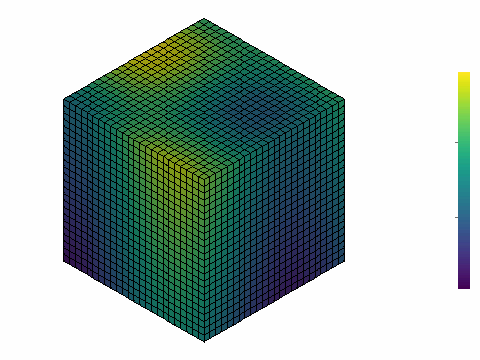

In [31]:
render(mapped, 'edges', 'all', 'color_by', 'f', 'cmap', 'viridis', 'colorbar', true)

## Cross-section (slice)

`mio.slice` computes the planar **cross-section** of a mesh -- the intersection with a plane, one
topological dimension below the cut cells. The input is simplexified first (marching tetrahedra), cut
points on shared edges are deduped (watertight), and `point_data` is interpolated at the cut. Unlike
`mio.crop_bbox`, which keeps whole cells on one side, `mio.slice` computes the intersection and lowers the
dimension.

section: 289 points, 128 faces


f: -0.855732 .. 1.83125 (viridis)
ticks: 0, 1


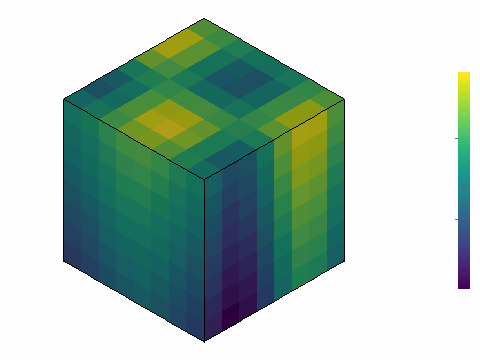

In [32]:
slice_vol = hex_block(8, 1.0 / 8.0);
ps = mio.points(slice_vol);
field = sin(6.0 * ps(:, 1)) .* cos(6.0 * ps(:, 2)) + ps(:, 3);
mio.add_point_data(slice_vol, 'f', field);

section = mio.slice(slice_vol, [0.5 0.5 0.5], [0 0 1]);
fprintf('section: %d points, %d faces\n', mio.num_points(section), mio.num_cells(section));

render(slice_vol, 'color_by', 'f', 'cmap', 'viridis', 'colorbar', true)

The section is a triangle mesh carrying the interpolated field. As plain arrays it is also a `trisurf`:
`mio.points` and `mio.connectivity` are exactly the shapes `trisurf` takes.

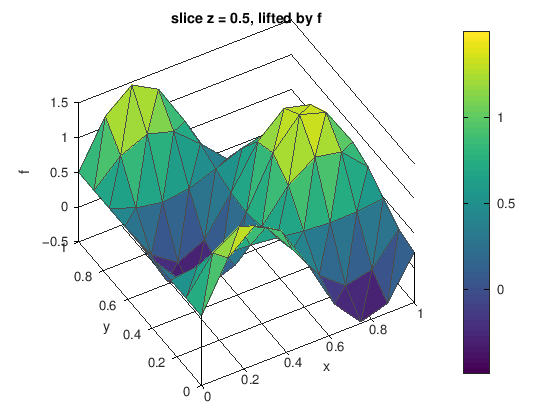

In [33]:
sp_sec = mio.points(section);
st_sec = mio.connectivity(section, 1);
fs_sec = mio.point_data(section, 'f');
figure();
trisurf(st_sec, sp_sec(:, 1), sp_sec(:, 2), fs_sec, fs_sec, 'edgecolor', [0.3 0.3 0.3]);
colorbar();
view(-30, 50);
xlabel('x');
ylabel('y');
zlabel('f');
title('slice z = 0.5, lifted by f', 'interpreter', 'none');

## Isosurfaces / contours

`mio.isosurface` computes the **level set** of a scalar `point_data` field -- the locus where the array
equals a given isovalue, one topological dimension below the cut cells. It is the *data-driven* sibling of
`mio.slice`. Several isovalues land in one mesh, tagged per cell with a Float64 `iso:value` and an Int64
`iso:index`. A `cell_data` name is rejected -- it is piecewise constant and has no level set.

contours: 1206 points, 1836 faces


distinct values of r on the contours: 0.2        0.32        0.44


iso:index is stored as int64


  contour 0 : 228 faces
  contour 1 : 588 faces
  contour 2 : 1020 faces


r: 0.515277 .. 0.798919 (viridis)
ticks: 0.6, 0.7


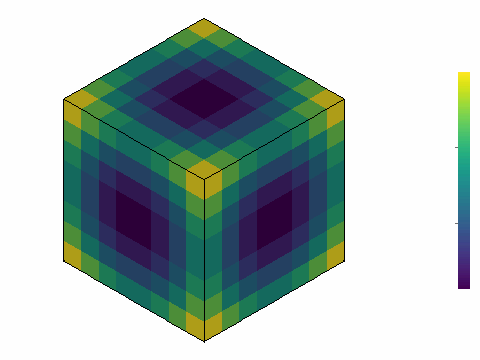

In [34]:
iso_vol = hex_block(8, 1.0 / 8.0);
pv = mio.points(iso_vol);
radius = sqrt((pv(:, 1) - 0.5) .^ 2 + (pv(:, 2) - 0.5) .^ 2 + (pv(:, 3) - 0.5) .^ 2);
mio.add_point_data(iso_vol, 'r', radius);

shells = mio.isosurface(iso_vol, 'r', [0.20 0.32 0.44]);
fprintf('contours: %d points, %d faces\n', mio.num_points(shells), mio.num_cells(shells));

levels = unique(round(mio.point_data(shells, 'r') * 1e10) / 1e10);
fprintf('distinct values of r on the contours: %s\n', num2str(levels'));
fprintf('iso:index is stored as %s\n', class(mio.cell_data(shells, 'iso:index', 1)));

[iso_pieces, iso_keys] = mio.split(shells, 'by', 'region', 'tag_name', 'iso:index');
for k = 1:numel(iso_pieces)
    fprintf('  contour %s : %d faces\n', iso_keys{k}, mio.num_cells(iso_pieces{k}));
end

render(iso_vol, 'color_by', 'r', 'cmap', 'viridis', 'colorbar', true)

The three shells are nested, so a cut-away through the centre shows all of them, coloured by `iso:index`.

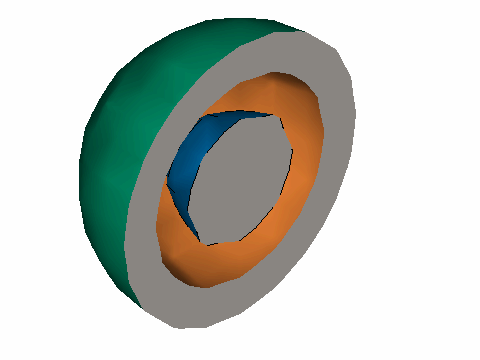

In [35]:
render(shells, 'color_by', 'iso:index', 'categorical', true, 'cutaway', [0.5 0.5 0.5 0 -1 0])

## Field derivatives -- gradient, divergence, curl

`mio.gradient` differentiates a `point_data` field: its **gradient**, **divergence** or **curl**.
Everything above transforms, transfers, summarizes or contours a field; this is what lets us
*differentiate* one -- the missing input for contouring a **derived** quantity and for gradient-based
error indicators.

**Green-Gauss** (the default) is exact for a linear field on any cell; **least-squares** fits over the
cells sharing a node and falls back to Green-Gauss -- counted, never silently wrong -- where the
neighbourhood is degenerate. Note that `'component'` is negative for **every** component here,
deliberately the opposite of `mio.isosurface`'s sentinel. A 3-component result comes back as an
`n x 3` array, one row per cell or point.

grad of a linear field: 3 -2  5  -- exact answer (3, -2, 5)


cells skipped: 0, fell back to Green-Gauss: 0


least-squares: 3 -2  5, fallbacks: 0


|grad r2|: min 0.0000, max 1.5155


isosurface of |grad r2|: 326 points, 516 faces


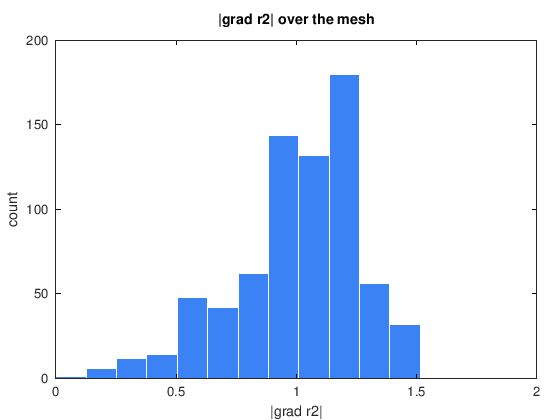

In [36]:
grad_vol = hex_block(8, 1.0 / 8.0);
gp = mio.points(grad_vol);
% A linear field, whose gradient is the known constant (3, -2, 5).
lin = 3.0 * gp(:, 1) - 2.0 * gp(:, 2) + 5.0 * gp(:, 3) + 7.0;
mio.add_point_data(grad_vol, 'f', lin);

g = mio.gradient(grad_vol, 'f');
gvals = mio.cell_data(g.mesh, 'f:gradient', 1);   % num_cells x 3
fprintf('grad of a linear field: %s  -- exact answer (3, -2, 5)\n', num2str(round(gvals(1, :) * 1e12) / 1e12));
fprintf('cells skipped: %d, fell back to Green-Gauss: %d\n', g.num_skipped, g.num_fallback);

% Least squares agrees, and reports its own fallbacks rather than hiding them.
l = mio.gradient(grad_vol, 'f', 'method', 'least-squares');
lvals = mio.cell_data(l.mesh, 'f:gradient', 1);
fprintf('least-squares: %s, fallbacks: %d\n', num2str(round(lvals(1, :) * 1e10) / 1e10), l.num_fallback);

% The composition: a non-linear field, its gradient magnitude at the points, and
% a contour of that DERIVED quantity.
radial = (gp(:, 1) - 0.5) .^ 2 + (gp(:, 2) - 0.5) .^ 2 + (gp(:, 3) - 0.5) .^ 2;
mio.add_point_data(grad_vol, 'r2', radial);
gr = mio.gradient(grad_vol, 'r2', 'location', 'point');
gvec = mio.point_data(gr.mesh, 'r2:gradient');   % num_points x 3
mag = sqrt(sum(gvec .^ 2, 2));
mio.add_point_data(gr.mesh, 'gradmag', mag);
fprintf('|grad r2|: min %.4f, max %.4f\n', min(mag), max(mag));

derived = mio.isosurface(gr.mesh, 'gradmag', 0.6);
fprintf('isosurface of |grad r2|: %d points, %d faces\n', mio.num_points(derived), mio.num_cells(derived));

mio_histogram(mag, '|grad r2| over the mesh', '|grad r2|')

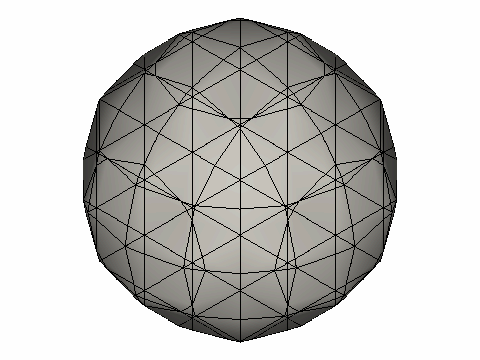

In [37]:
render(derived, 'edges', 'all')

Every operation shown here is also exposed through the C API, the Fortran module, the Julia and R
bindings, and the WebAssembly build, and as a `meshioplusplus` CLI verb.

## Data operations

The operations above reshape *geometry*. The **data operations** act on
`point_data`/`cell_data`/`field_data` and never touch geometry. A quick walk through all five on the
surface mesh.

In [38]:
surfD = viz_corner;   % handles share: this adds the arrays to viz_corner too, as in R
pD = mio.points(surfD);
cx = mean(pD(:, 1));
cy = mean(pD(:, 2));

vel = [-(pD(:, 2) - cy), pD(:, 1) - cx, 0.3 * pD(:, 3)];
mio.add_point_data(surfD, 'velocity', vel);
mio.add_point_data(surfD, 'height', pD(:, 3));

show_data_info = @(rows) arrayfun(@(a) fprintf( ...
    '  %s %s comp=%d entries=%d min=%.6f max=%.6f mean=%.6f\n', a.location, a.name, ...
    a.num_components, a.num_entries, a.min, a.max, a.mean), rows);
disp('before:');
show_data_info(mio.data_info(surfD));

before:


  point height comp=1 entries=71 min=0.000000 max=0.125244 mean=0.045108
  point velocity comp=3 entries=71 min=-0.102238 max=0.099902 mean=0.004511


speed range: 0.015887 -> 0.135876


speed: 0.0189714 .. 0.127347 (viridis)
ticks: 0.05, 0.1


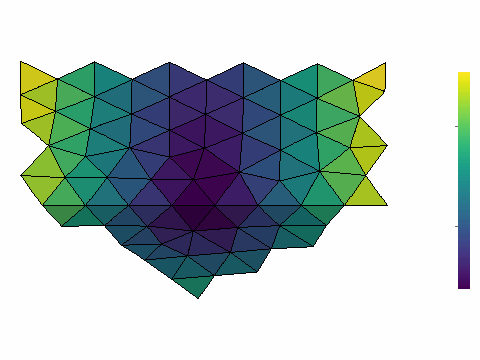

In [39]:
% mio.data_calc: a small expression language (+ - * /, abs/sqrt/min/max/norm).
with_speed = mio.data_calc(surfD, 'norm(velocity)', 'speed');
sp2 = mio.point_data(with_speed, 'speed');
fprintf('speed range: %.6f -> %.6f\n', min(sp2), max(sp2));
render(with_speed, 'edges', 'all', 'color_by', 'speed', 'cmap', 'viridis', 'colorbar', true)

speed_cell: 0.0189714 .. 0.127347 (viridis)
ticks: 0.05, 0.1


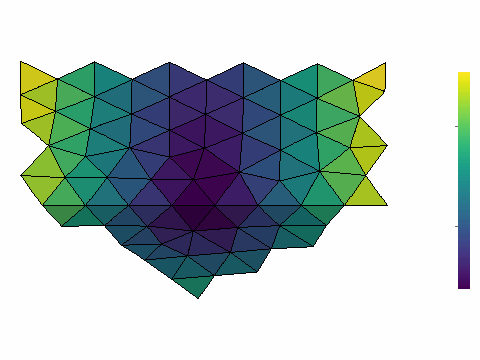

In [40]:
% mio.data_point_to_cell / mio.data_cell_to_point: move between locations. The round trip acts as a
% smoothing pass; the cell values are piecewise constant.
to_cell = mio.data_point_to_cell(with_speed, 'names', 'speed', 'suffix', '_cell');
back2 = mio.data_cell_to_point(to_cell, 'names', 'speed_cell', 'weight', 'measure');
render(to_cell, 'edges', 'all', 'color_by', 'speed_cell', 'cmap', 'viridis', 'colorbar', true)

speed_cell: 0.0248687 .. 0.120577 (viridis)
ticks: 0.04, 0.06, 0.08, 0.1, 0.12


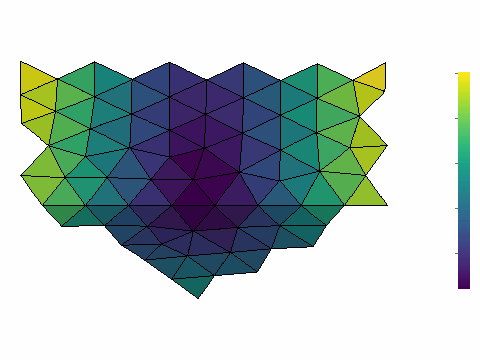

In [41]:
render(back2, 'edges', 'all', 'color_by', 'speed_cell', 'cmap', 'viridis', 'colorbar', true)

normalized range: 0.000000 -> 1.000000


speed_n: 0.0257087 .. 0.928919 (viridis)
ticks: 0.2, 0.4, 0.6, 0.8


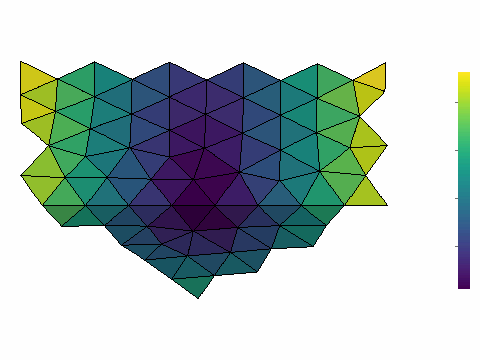

In [42]:
% mio.data_condition: clamp / normalize / standardize, without touching geometry.
normd = mio.data_condition(with_speed, 'point', 'names', 'speed', 'cond_mode', 'normalize', 'suffix', '_n');
nd = mio.point_data(normd, 'speed_n');
fprintf('normalized range: %.6f -> %.6f\n', min(nd), max(nd));
render(normd, 'edges', 'all', 'color_by', 'speed_n', 'cmap', 'viridis', 'colorbar', true)

In [43]:
% rename / drop: tidy up and confirm the geometry never moved.
tidy = mio.data_rename(normd, 'point', 'speed_n', 'speed_normalized');
tidy = mio.data_drop(tidy, 'point', 'speed');
disp('after rename + drop:');
show_data_info(mio.data_info(tidy));

same_pts = mio.num_points(surfD) == mio.num_points(tidy);
same_cells = mio.num_cells(surfD) == mio.num_cells(tidy);
same_coords = isequal(mio.points(surfD), mio.points(tidy));
fprintf('\ngeometry unchanged -- points: %d | cell count: %d | coordinates bit-identical: %d\n', ...
    same_pts, same_cells, same_coords);

after rename + drop:


  point height comp=1 entries=71 min=0.000000 max=0.125244 mean=0.045108
  point speed_normalized comp=1 entries=71 min=0.000000 max=1.000000 mean=0.478844
  point velocity comp=3 entries=71 min=-0.102238 max=0.099902 mean=0.004511



geometry unchanged -- points: 1 | cell count: 1 | coordinates bit-identical: 1


## Transient sequences (multi-file datasets)

Most formats cannot express time at all, so transient solver output usually
arrives as a *set* of files -- `out_0000.vtu ... out_0500.vtu`. `mio.sequence()`
treats such a set as **one ordered dataset**: it holds only the entry *plan*
(paths, per-file step indices, times) and reads one step at a time via
`mio.sequence_read()`; `mio.sequence_to_timeseries()` fans a set **in** to one
multi-step XDMF, and `mio.timeseries_to_sequence()` fans one **out** to a file
per step.

Two things are contracts rather than conveniences. Ordering is
**natural-numeric**, so `seq_10.vtu` follows `seq_9.vtu` (a lexicographic sort
gets that backwards). And the drivers **stream**: at most one mesh is alive at
a time, so a 500-step dataset costs no more memory than a one-step one.

`mio.sequence_to_timeseries(..., 'ascii', true)` selects XDMF's `"XML"` data
format instead of the default `"HDF"`, so this works with or without HDF5 in the
C library.

In [44]:
% A synthetic time series: the hex block, oscillating along z. Deliberately
% UNPADDED filenames, so the natural-numeric ordering rule has something to
% prove: a lexicographic sort would put seq_10 third, not last.
seq_dir = tempname();
mkdir(seq_dir);
n_steps = 12;
for k = 0:n_steps - 1
    step = hex_block(4);
    p = mio.points(step);
    p(:, 3) = p(:, 3) + 1.5 * sin(2 * pi * k / n_steps);
    mio.set_points(step, p);
    mio.add_point_data(step, 'height', p(:, 3));
    mio.write(step, fullfile(seq_dir, sprintf('seq_%d.vtu', k)));
end

seq = mio.sequence(fullfile(seq_dir, 'seq_*.vtu'));
n = mio.sequence_count(seq);
fprintf('%d steps, in natural-numeric order:\n', n);
step_names = cell(1, n);
step_times = zeros(1, n);
for i = 1:n
    [~, stem, ext] = fileparts(mio.sequence_path(seq, i));
    step_names{i} = [stem ext];
    step_times(i) = mio.sequence_time(seq, i);
end
fprintf('  %s\n', strjoin(step_names, ' '));
fprintf('  a lexicographic sort would put seq_10 third, not last.\n');
fprintf('  times: %s  (source: %s)\n', num2str(step_times), mio.sequence_time_source(seq, 1));

12 steps, in natural-numeric order:


  seq_0.vtu seq_1.vtu seq_2.vtu seq_3.vtu seq_4.vtu seq_5.vtu seq_6.vtu seq_7.vtu seq_8.vtu seq_9.vtu seq_10.vtu seq_11.vtu


  a lexicographic sort would put seq_10 third, not last.


  times: 0   1   2   3   4   5   6   7   8   9  10  11  (source: filename)


In [45]:
% Fan-in: 12 single-step files -> one multi-step XDMF, streaming.
% 'ascii', true selects the "XML" data format -- no HDF5 needed.
series = fullfile(seq_dir, 'series.xdmf');
mio.sequence_to_timeseries(seq, series, 'ascii', true);
mio.sequence_free(seq);

series_seq = mio.sequence(series);
fprintf('fan-in -> series.xdmf (%d steps; times now come from the file itself: %s)\n', ...
    mio.sequence_count(series_seq), mio.sequence_time_source(series_seq, 4));
mio.sequence_free(series_seq);

% Fan-out: back to one file per step, {step} zero-padded to four digits.
mio.timeseries_to_sequence(series, fullfile(seq_dir, 'back_{step}.vtu'));
fprintf('fan-out -> back_0000.vtu ... back_0011.vtu\n');

% A transient post-processing run: the chain is applied to EVERY step.
settings = fullfile(seq_dir, 'settings.json');
fid = fopen(settings, 'w');
fprintf(fid, '{"Version": 1, "Input": {"Pattern": "%s"}, "Operations": [{"Op": "Quality"}], "Output": {"Path": "%s"}}\n', ...
    fullfile(seq_dir, 'seq_*.vtu'), fullfile(seq_dir, 'post_{step}.vtu'));
fclose(fid);
mio.sequence_pipeline_run_file(settings);
fprintf('per-step pipeline: wrote %d post_*.vtu file(s) with quality metrics\n', ...
    numel(dir(fullfile(seq_dir, 'post_*.vtu'))));

fan-in -> series.xdmf (12 steps; times now come from the file itself: file)


fan-out -> back_0000.vtu ... back_0011.vtu


per-step pipeline: wrote 12 post_*.vtu file(s) with quality metrics


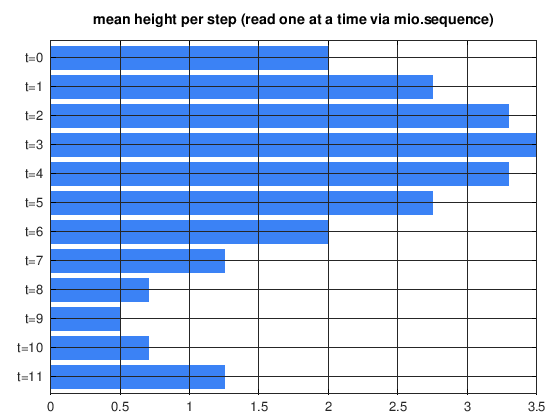

In [46]:
% The whole series in one chart: every step's mean height, read ONE AT A TIME
% via mio.sequence's random access (mio.sequence_read) -- the same handle that
% gave the lazy traversal above also gives repeatable, indexed access.
back_seq = mio.sequence(fullfile(seq_dir, 'back_*.vtu'));
nb = mio.sequence_count(back_seq);
means = zeros(1, nb);
step_labels = cell(1, nb);
for i = 1:nb
    m = mio.sequence_read(back_seq, i);
    means(i) = mean(mio.point_data(m, 'height'));
    step_labels{i} = sprintf('t=%d', round(mio.sequence_time(back_seq, i)));
end
mio.sequence_free(back_seq);
mio_bar_chart(step_labels, means, 'mean height per step (read one at a time via mio.sequence)')

## Selective reads: loading only what you need

`mio.read` takes `'points_only'` (geometry only, no data arrays) and `'arrays'` (only the named arrays).
`mio.read_metadata` skips the heavy arrays entirely and reports whether it had to fall back to a full read
(`fell_back`).

In [47]:
sel_mesh = mio.extract_surface(mesh);
psel = mio.points(sel_mesh);
radius = sqrt(sum((psel - mean(psel, 1)) .^ 2, 2));
mio.add_point_data(sel_mesh, 'radius', radius);
sel_path = mio_nb_temp_path('_selective.vtu');
mio.write(sel_mesh, sel_path);

full = mio.read(sel_path);
bare = mio.read(sel_path, 'points_only', true);
meta = mio.read_metadata(sel_path);

fprintf('full read      : point_data arrays= %d\n', numel(mio.point_data_names(full)));
fprintf('points_only    : point_data arrays= %d\n', numel(mio.point_data_names(bare)));
fprintf('read_metadata  : %d points, %d cells, arrays= %d\n', meta.num_points, meta.num_cells, ...
    numel(meta.point_data_names));
fprintf('summary was cheap (no fallback): %d\n\n', ~meta.fell_back);
fprintf('same geometry, no data arrays: %d\n', numel(mio.point_data_names(bare)) == 0);

full read      : point_data arrays= 1


points_only    : point_data arrays= 0


read_metadata  : 29151 points, 58394 cells, arrays= 1


summary was cheap (no fallback): 1



same geometry, no data arrays: 1


Reading the numbers honestly: `'points_only'` still decodes and transfers connectivity, which is never
skipped, so the win depends on how data-heavy a given file is. `mio.read_metadata` is the consistent win:
it decodes neither coordinates nor connectivity, only the array headers.